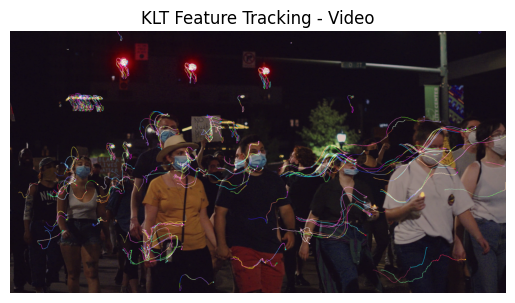

In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from IPython.display import clear_output

# -------------------------------
# 1. Open Video
# -------------------------------
video_path = r"E:\projects\assg3\assg3\4766165-uhd_4096_2160_24fps.mp4"
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Error: Cannot open video")
    cap.release()

ret, old_frame = cap.read()
if not ret:
    print("Error: Cannot read first frame")
    cap.release()

old_gray = cv2.cvtColor(old_frame, cv2.COLOR_BGR2GRAY)

# -------------------------------
# 2. Detect Initial Corners
# -------------------------------
def detect_features(gray):
    return cv2.goodFeaturesToTrack(
        gray,
        maxCorners=200,
        qualityLevel=0.01,
        minDistance=10
    )

prev_points = detect_features(old_gray)

lk_params = dict(
    winSize=(15, 15),
    maxLevel=2,
    criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03)
)

color = np.random.randint(0, 255, (200, 3))
mask = np.zeros_like(old_frame)

plt.figure(figsize=(8,6))

# -------------------------------
# 3. Process Frames
# -------------------------------
while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        print("Video Ended")
        break

    frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # If no features available, re-detect
    if prev_points is None or len(prev_points) < 10:
        prev_points = detect_features(frame_gray)
        mask = np.zeros_like(frame)
        old_gray = frame_gray.copy()
        continue

    new_points, status, error = cv2.calcOpticalFlowPyrLK(
        old_gray, frame_gray, prev_points, None, **lk_params
    )

    if new_points is None:
        prev_points = detect_features(frame_gray)
        old_gray = frame_gray.copy()
        continue

    good_new = new_points[status == 1]
    good_old = prev_points[status == 1]

    for i, (new, old) in enumerate(zip(good_new, good_old)):
        x_new, y_new = new.ravel()
        x_old, y_old = old.ravel()

        mask = cv2.line(mask, (int(x_new), int(y_new)),
                        (int(x_old), int(y_old)),
                        color[i % len(color)].tolist(), 2)

        frame = cv2.circle(frame, (int(x_new), int(y_new)), 5,
                           color[i % len(color)].tolist(), -1)

    output = cv2.add(frame, mask)

    clear_output(wait=True)
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title("KLT Feature Tracking - Video")
    plt.show()

    old_gray = frame_gray.copy()
    prev_points = good_new.reshape(-1, 1, 2)

cap.release()
